# 03A OFDM 系统仿真实验（学生版）

本实验参考《无线通信系统仿真》（25版）中的**“开放性综合实验一：OFDM 系统仿真”**（教材第 21~28 页）。

## 1. 实验原理与教学目的

正交频分复用（OFDM, Orthogonal Frequency Division Multiplexing）是一种高效的多载波并行传输技术。它将高速串行数据流分配到 $N$ 个互相正交的子载波上并行传输，使得每个子载波上的符号周期扩大 $N$ 倍，从而极大降低了无线信道时间弥散性（多径时延扩展）带来的符号间干扰（ISI）。

### 1.1 子载波正交性与 IFFT/FFT 实现
- **正交性条件**：各子载波频率间隔满足 $\Delta f = 1/T$（$T$ 为 OFDM 符号有效周期）。在符号周期内任意两个不同载波乘积积分为零：
  $$\int_{0}^{T} e^{j 2\pi f_i t} e^{-j 2\pi f_k t} dt = 0 \quad (i \neq k)$$
- **离散变换实现**：根据离散傅里叶变换原理，OFDM 调制可直接利用逆离散傅里叶变换（IDFT/IFFT）高效实现，接收端解调则对应离散傅里叶变换（DFT/FFT）：
  $$x[n] = \frac{1}{\sqrt{N}} \sum_{k=0}^{N-1} X[k] e^{j \frac{2\pi}{N} k n}, \quad n = 0, 1, \dots, N-1$$
  $$Y[k] = \frac{1}{\sqrt{N}} \sum_{n=0}^{N-1} y[n] e^{-j \frac{2\pi}{N} k n}, \quad k = 0, 1, \dots, N-1$$

### 1.2 保护间隔与循环前缀（CP）
- **消除符号间干扰（ISI）**：在符号间插入长度为 $N_{cp}$ 的保护间隔，只要 $N_{cp} \ge \tau_{max}$（最大多径时延扩展），前一符号的多径拖尾只落在当前符号的保护间隔内，接收端丢弃保护间隔后即可彻底消除符号间干扰。
- **循环前缀机制**：保护间隔采用符号尾部波形的周期性复制（循环前缀 CP）。这样多径信道的时域**线性卷积**在去除 CP 后等效转化为**循环卷积**：
  $$y[n] = (h \circledast x)[n] + w[n]$$
- **消除载波间干扰（ICI）**：频域循环卷积经 FFT 变换后，直接对角化解耦为各个独立子载波上的标量乘积：
  $$Y[k] = H[k] X[k] + W[k]$$
  各子载波正交性得以保持，完全消除了子载波间串扰（ICI）。

### 1.3 频域单抽头迫零均衡（Zero-Forcing, ZF）
由于每个子载波上的频率选择性衰落转化为平坦衰落，接收机只需利用单抽头复数除法即可恢复发送符号：
$$\hat{X}[k] = \frac{Y[k]}{H[k]} = X[k] + \frac{W[k]}{H[k]}$$

### 1.4 导频插入与 LS 信道估计
在实际无线通信中，信道冲击响应未知。发射端在特定时频位置发送接收端已知的导频（Pilot）符号 $X_p[k]$：
$$Y_p[k] = H[k] X_p[k] + W_p[k]$$
接收端利用最小二乘（Least Squares, LS）准则估计子载波处的信道频域响应：
$$\hat{H}_{LS}[k] = \frac{Y_p[k]}{X_p[k]} = H[k] + \frac{W_p[k]}{X_p[k]}$$
随后利用 $\hat{H}_{LS}[k]$ 对同一相干块内的数据符号进行迫零均衡。

## 2. 实验参数与设计内容（对标教材）
- **子载波数**：$N = 64$
- **标称循环前缀长度**：$N_{cp} = 16$
- **调制方式**：QPSK（自主实现映射与硬判决解映射，能量归一化 $E_s = 1$）
- **多径信道模型**：3 径典型瑞利衰落模型
  - 各径时延：`path_delays = [0, 1, 4]`（最大时延 $\tau_{max} = 4$）
  - 各径平均功率：`path_gains = [0.8, 0.8, 0.8]`（功率归一化）
  - 各径复增益服从零均值循环对称复高斯分布
- **实验任务**：
  1. **模块一**：补全 OFDM 核心收发机链路函数（QPSK 自主映射/解映射、IFFT+CP 发射、去CP+FFT 接收、频域 ZF 均衡）；
  2. **模块二（基本实验）**：完成多径瑞利衰落信道与 AWGN 信道下的性能对比仿真，绘制 BER-Eb/N0 曲线并与理论公式对比；
  3. **模块三（拓展实验一）**：扫描保护间隔 CP 长度，研究其与最大多径时延 $\tau_{max}$ 的关系，观察分析误码平台；
  4. **模块四（拓展实验二）**：实现基于导频的 LS 信道估计，并与理想已知信道（Ideal CSI）进行 BER 性能对比。


In [1]:
# 模块一：环境准备与 OFDM 链路核心函数
from pathlib import Path
import sys

# 从当前目录向上查找 src/sionna，优先使用本仓库源码。
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import torch
import matplotlib.pyplot as plt
import scipy.special as sp

# OFDM 链路只用到 AWGN 模块（多径衰落由自定义抽头 + 卷积实现）。
from sionna.phy.channel import AWGN

# 设置 Matplotlib 中文字体，避免图标题和坐标轴中文乱码。
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "Noto Sans CJK SC",
    "Arial Unicode MS",
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False

# Word 报告中的图宽约 14.4 cm，而画布按英寸设置，插入时会被缩放，
# 因此把 matplotlib 的字号整体放大，使打印后的字号与正文（10.5 pt）接近。
plt.rcParams.update(
    {
        "font.size": 13,
        "axes.labelsize": 13,
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)

# 固定使用 CPU，保证没有 GPU 的学生电脑也能运行。
DEVICE = "cpu"
PRECISION = "single"

# 固定随机种子，便于复现实验结果。
# Sionna 的 AWGN / 衰落信道使用自己的 torch.Generator（config.torch_rng），
# 因此除 torch / numpy 外还必须设置 sionna.phy.config.seed。
from sionna.phy import config as sionna_config


def set_seed(seed=42):
    """固定 Python / NumPy / PyTorch / Sionna 四个随机源，使仿真结果可复现。"""
    torch.manual_seed(seed)
    np.random.seed(seed)
    sionna_config.seed = int(seed)


set_seed(42)

# 图、数据输出目录：便于把过程性与结果性材料归档到同一文件夹。
FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

# --- 系统基础仿真参数（完全对标教材第 23~24 页）---
NUM_SUBCARRIERS = 64  # FFT 长度 / 子载波数 N
DEFAULT_CP_LEN = 16   # 默认循环前缀 (CP) 长度
BITS_PER_SYMBOL = 2   # QPSK 调制每个符号包含的比特数

# 3 径瑞利衰落信道参数（教材参数：path_delays=[0, 1, 4], path_gains=[0.8, 0.8, 0.8]）
PATH_DELAYS = [0, 1, 4]
MAX_PATH_DELAY = max(PATH_DELAYS)  # 最大多径时延 tau_max = 4
RAW_GAINS = torch.tensor([0.8, 0.8, 0.8], dtype=torch.float32, device=DEVICE)
# 对径功率做归一化，使得平均信道增益 E[|h|^2] = 1.0，与理论 BER 曲线严格对齐
PATH_GAINS = RAW_GAINS / torch.sqrt(torch.sum(RAW_GAINS ** 2))


# 将 Eb/N0 (dB) 换算成 AWGN 模块所需的复噪声方差 no：no = 1/(Eb/N0 * log2(M))
def ebno_db_to_no(ebno_db, nbits, coderate=1.0):
    ebno = torch.as_tensor(ebno_db, dtype=torch.float32, device=DEVICE)
    return 1.0 / (10.0 ** (ebno / 10.0) * nbits * coderate)


def qpsk_modulate(bits):
    """自主实现 QPSK 星座映射（能量归一化 Es = 1）。

    输入 bits 形状: (..., 2)，每个元素取值为 0 或 1。
    映射规则: s = ((1 - 2*b0) + 1j * (1 - 2*b1)) / sqrt(2)
    """
    bits = bits.to(torch.float32)
    b0 = 1.0 - 2.0 * bits[..., 0]
    b1 = 1.0 - 2.0 * bits[..., 1]
    return (b0 + 1j * b1).to(torch.complex64) / np.sqrt(2.0)


def qpsk_demodulate(symbols):
    """自主实现 QPSK 硬判决解映射。

    实部 > 0 判决为 0，否则判为 1；虚部 > 0 判决为 0，否则判为 1。
    输出形状为 (..., 2) 的判决比特。
    """
    b0 = (symbols.real < 0).to(torch.int32)
    b1 = (symbols.imag < 0).to(torch.int32)
    return torch.stack([b0, b1], dim=-1)


def ofdm_modulate(symbols, cp_len):
    """OFDM 发射机：频域到时域 IFFT 变换并添加循环前缀 (CP)。

    完全对标教材公式: time_domain_ofdm = sqrt(N) * ifft(symbols, N)
    """
    # 频域 -> 时域：sqrt(N) * IDFT，使时域样点平均能量保持为 Es
    time_sym = torch.fft.ifft(symbols, dim=-1) * np.sqrt(NUM_SUBCARRIERS)
    if cp_len > 0:
        # 循环前缀：复制符号尾部 cp_len 个样点放到符号前面
        time_sym = torch.cat([time_sym[..., -cp_len:], time_sym], dim=-1)
    return time_sym


def ofdm_demodulate(rx_time, cp_len):
    """OFDM 接收机：丢弃循环前缀 (CP) 并进行 FFT 变换回到频域。

    完全对标教材公式: rx_freq = (1 / sqrt(N)) * fft(rx_no_cp, N)
    """
    if cp_len > 0:
        rx_no_cp = rx_time[..., cp_len:]
    else:
        rx_no_cp = rx_time
    # 时域 -> 频域：(1/sqrt(N)) * DFT，与发射端构成酉变换对
    return torch.fft.fft(rx_no_cp, dim=-1) / np.sqrt(NUM_SUBCARRIERS)


def zf_equalize(rx_freq, channel_freq):
    """频域单抽头迫零 (Zero-Forcing) 均衡器。"""
    # 每个子载波上做复数除法：X_hat[k] = Y[k] / H[k]
    # 极小值保护：避免深衰落子载波除零导致 inf
    return rx_freq / (channel_freq + 1e-12)


def count_bit_errors(b, b_hat):
    """统计误比特数。"""
    return int(torch.sum(b.to(torch.int32) != b_hat.to(torch.int32)).item())


def ber(b, b_hat):
    """计算误比特率 BER。"""
    return count_bit_errors(b, b_hat) / b.numel()


def theory_awgn_ber(ebno_db):
    """QPSK 在 AWGN 信道下的理论 BER: Pb = Q(sqrt(2 * Eb/N0)) = 0.5 * erfc(sqrt(Eb/N0))。"""
    ebno_linear = 10.0 ** (np.asarray(ebno_db) / 10.0)
    return 0.5 * sp.erfc(np.sqrt(ebno_linear))


def theory_rayleigh_ber(ebno_db):
    """未编码 QPSK 在单抽头瑞利衰落信道下的理论 BER: Pb = 0.5 * (1 - sqrt(gamma / (1 + gamma)))。"""
    gamma = 10.0 ** (np.asarray(ebno_db) / 10.0)
    return 0.5 * (1.0 - np.sqrt(gamma / (1.0 + gamma)))


# --- 多径信道与 OFDM 链路的公共辅助函数 ---
def sample_multipath_taps(batch_size):
    """生成 3 径瑞利衰落信道的复增益, 形状 (batch_size, P)。"""
    real = torch.randn(batch_size, len(PATH_DELAYS), dtype=torch.float32, device=DEVICE)
    imag = torch.randn(batch_size, len(PATH_DELAYS), dtype=torch.float32, device=DEVICE)
    taps = (real + 1j * imag) / np.sqrt(2.0)
    return taps.to(torch.complex64) * PATH_GAINS.to(torch.complex64)


def channel_frequency_response(taps):
    """由时域多径抽头计算各子载波频域响应 H[k]，形状 (batch_size, N)。"""
    k = torch.arange(NUM_SUBCARRIERS, dtype=torch.float32, device=DEVICE)
    delays = torch.tensor(PATH_DELAYS, dtype=torch.float32, device=DEVICE)
    # exp(-j 2*pi*k*tau/N): (N, P)
    delay_phase = torch.exp(-2j * np.pi * torch.outer(k, delays) / NUM_SUBCARRIERS)
    return taps @ delay_phase.T


def apply_multipath_time(stream, taps):
    """对流式时域信号做多径线性卷积（按各径时延移位后加权求和）。"""
    total_len = stream.shape[-1]
    out = torch.zeros_like(stream)
    for p, d in enumerate(PATH_DELAYS):
        coeff = taps[:, p].unsqueeze(-1)
        if d == 0:
            shifted = stream
        else:
            shifted = torch.cat(
                [torch.zeros_like(stream[..., :d]), stream[..., : total_len - d]], dim=-1
            )
        out = out + coeff * shifted
    return out


def extract_ofdm_symbols(stream, num_symbols, cp_len):
    """从连续时域流中逐符号去 CP 并做 FFT，返回频域符号 (batch, num_symbols, N)。"""
    block_len = NUM_SUBCARRIERS + cp_len
    windows = []
    for i in range(num_symbols):
        start = i * block_len + cp_len
        windows.append(stream[:, start : start + NUM_SUBCARRIERS])
    windows = torch.stack(windows, dim=1)
    return ofdm_demodulate(windows, 0)  # 已手动去 CP，此处直接 FFT


正在执行基本实验：QPSK-OFDM 在多径瑞利衰落信道与 AWGN 信道下的性能仿真...


图10  QPSK-OFDM 在 AWGN 与多径瑞利衰落信道下的误码性能


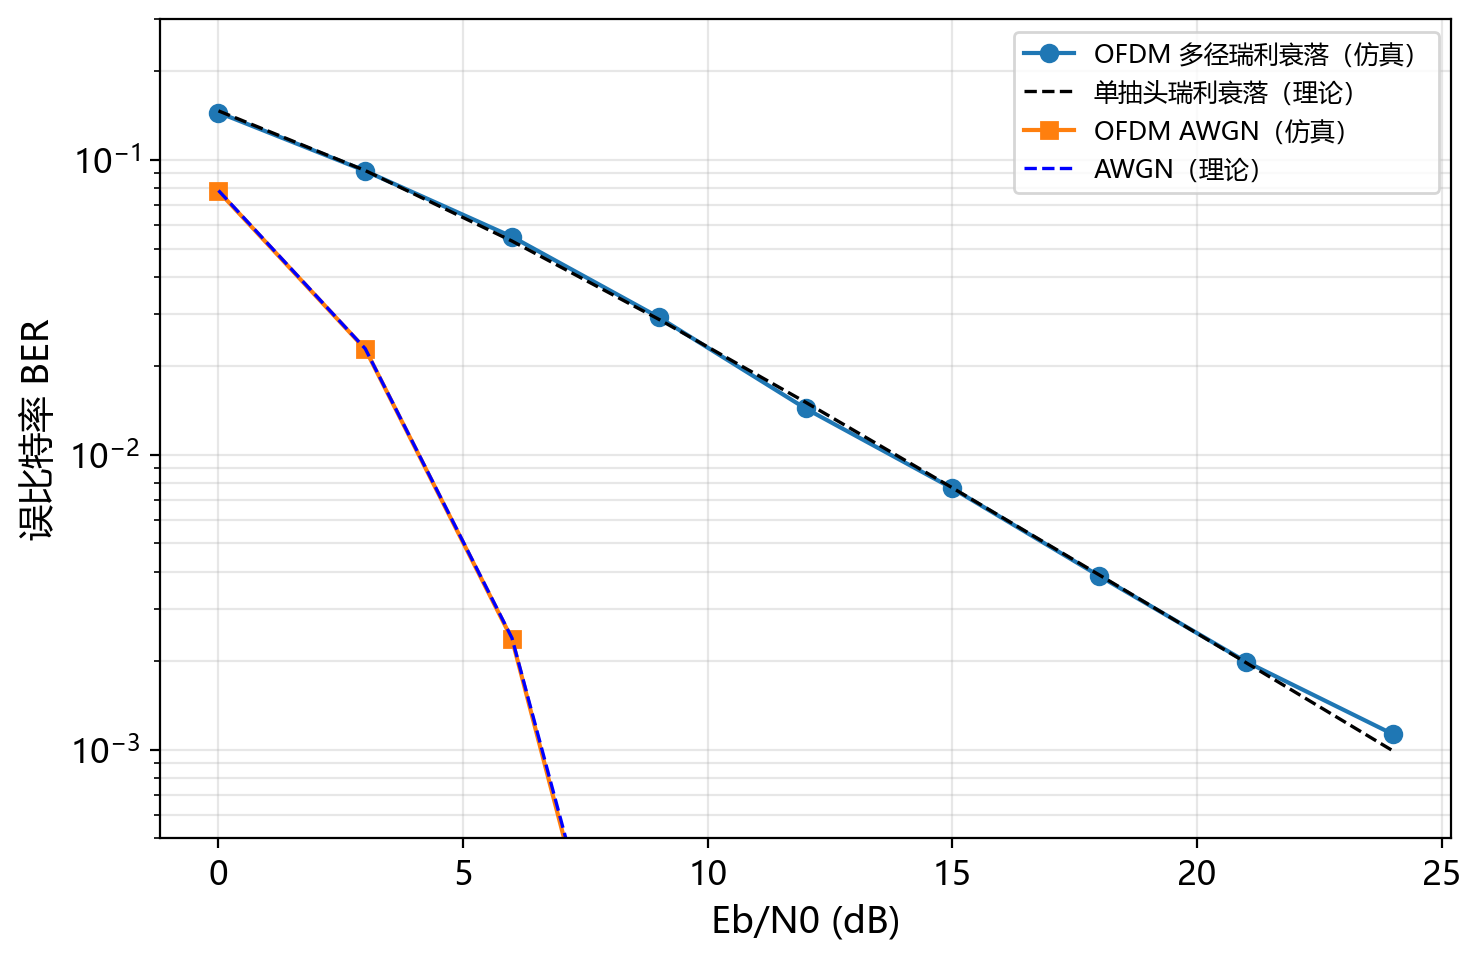

表 5  基本实验：QPSK-OFDM 的 BER 仿真与理论值
 EbN0_dB  BER_多径瑞利_仿真  BER_单抽头瑞利_理论  BER_AWGN_仿真   BER_AWGN_理论
       0     0.144501      0.146447     0.078186  7.864960e-02
       3     0.091634      0.091913     0.022812  2.287841e-02
       6     0.054818      0.052999     0.002368  2.388291e-03
       9     0.029239      0.028782     0.000030  3.362723e-05
      12     0.014345      0.015065     0.000000  9.006010e-09
      15     0.007691      0.007723     0.000000  9.123957e-16
      18     0.003883      0.003916     0.000000  1.396014e-29
      21     0.001988      0.001974     0.000000  5.299697e-57
      24     0.001130      0.000992     0.000000 1.444419e-111
基本实验仿真完成并通过断言检验！


In [2]:
# 模块二（基本实验）：多径瑞利衰落信道 vs. AWGN 信道下的 QPSK-OFDM 系统性能仿真
# 完全对标教材第 23~27 页基本实验脚本逻辑与理论对比曲线

def simulate_basic_ofdm(ebno_db_range, num_blocks=1000, symbols_per_block=10):
    """仿真 QPSK-OFDM 在多径瑞利信道与 AWGN 信道下的误码率特性。"""
    ber_rayleigh_list = []
    ber_awgn_list = []

    N = NUM_SUBCARRIERS
    cp = DEFAULT_CP_LEN
    block_len = N + cp

    for ebno_db in ebno_db_range:
        no = ebno_db_to_no(float(ebno_db), BITS_PER_SYMBOL).item()

        # 1) 发送端：随机比特 -> QPSK 映射 -> IFFT + CP -> 连续时域符号流
        bits = torch.randint(
            0,
            2,
            (num_blocks, symbols_per_block, N, BITS_PER_SYMBOL),
            dtype=torch.int32,
            device=DEVICE,
        )
        freq_sym = qpsk_modulate(bits)                                  # (B, S, N)
        time_sym = ofdm_modulate(freq_sym, cp)                          # (B, S, L)
        stream = time_sym.reshape(num_blocks, symbols_per_block * block_len)

        # 2) 每个块（帧）抽取一次 3 径瑞利信道，并计算该帧的频域响应 H[k]
        taps = sample_multipath_taps(num_blocks)
        h_freq = channel_frequency_response(taps)                       # (B, N)

        # 3) 多径信道传输 + AWGN
        rx_multipath = apply_multipath_time(stream, taps)
        rx_multipath = AWGN(precision=PRECISION, device=DEVICE)(rx_multipath, no)
        # 用于对比的纯 AWGN 信道（等效 H[k] = 1）
        rx_awgn = AWGN(precision=PRECISION, device=DEVICE)(stream, no)

        # 4) 接收端：去 CP + FFT + 频域迫零均衡 + QPSK 解映射
        rx_freq_mp = extract_ofdm_symbols(rx_multipath, symbols_per_block, cp)
        rx_eq_mp = zf_equalize(rx_freq_mp, h_freq.unsqueeze(1))
        bits_hat_mp = qpsk_demodulate(rx_eq_mp)

        rx_freq_aw = extract_ofdm_symbols(rx_awgn, symbols_per_block, cp)
        bits_hat_aw = qpsk_demodulate(rx_freq_aw)  # H[k] = 1，无需均衡

        ber_rayleigh_list.append(ber(bits, bits_hat_mp))
        ber_awgn_list.append(ber(bits, bits_hat_aw))

    return np.array(ber_rayleigh_list), np.array(ber_awgn_list)


# 设定信噪比扫描范围 (dB)
ebno_range_basic = np.arange(0, 26, 3)

print("正在执行基本实验：QPSK-OFDM 在多径瑞利衰落信道与 AWGN 信道下的性能仿真...")
ber_sim_rayleigh, ber_sim_awgn = simulate_basic_ofdm(ebno_range_basic, num_blocks=1000, symbols_per_block=10)

# 计算对应的理论误码率
ber_theory_ray = theory_rayleigh_ber(ebno_range_basic)
ber_theory_awg = theory_awgn_ber(ebno_range_basic)

# 绘制误码率性能对比曲线 (包含仿真瑞利、仿真AWGN、理论瑞利、理论AWGN四条曲线)
fig, ax = plt.subplots(figsize=(7.6, 5.0))
ber_sim_rayleigh_plot = [v if v > 0 else np.nan for v in ber_sim_rayleigh]
ber_sim_awgn_plot = [v if v > 0 else np.nan for v in ber_sim_awgn]
ax.semilogy(ebno_range_basic, ber_sim_rayleigh_plot, "o-", lw=1.5, ms=6, label="OFDM 多径瑞利衰落（仿真）")
ax.semilogy(ebno_range_basic, ber_theory_ray, "k--", lw=1.2, label="单抽头瑞利衰落（理论）")
ax.semilogy(ebno_range_basic, ber_sim_awgn_plot, "s-", lw=1.5, ms=6, label="OFDM AWGN（仿真）")
ax.semilogy(ebno_range_basic, ber_theory_awg, "b--", lw=1.2, label="AWGN（理论）")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(5e-4, 0.3)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "03A_basic_ber.png", dpi=200, bbox_inches="tight")
print("图10  QPSK-OFDM 在 AWGN 与多径瑞利衰落信道下的误码性能")
plt.show()

# 数值表（结果性数据）
import pandas as pd

df_basic = pd.DataFrame(
    {
        "EbN0_dB": ebno_range_basic,
        "BER_多径瑞利_仿真": ber_sim_rayleigh,
        "BER_单抽头瑞利_理论": ber_theory_ray,
        "BER_AWGN_仿真": ber_sim_awgn,
        "BER_AWGN_理论": ber_theory_awg,
    }
)
print("表 5  基本实验：QPSK-OFDM 的 BER 仿真与理论值")
print(df_basic.to_string(index=False))
df_basic.to_csv(DATA_DIR / "03A_basic_ber.csv", index=False, encoding="utf-8-sig")

# 验证断言
assert len(ber_sim_rayleigh) == len(ebno_range_basic), "仿真结果长度与 Eb/N0 范围不符"
assert ber_sim_rayleigh[0] > ber_sim_rayleigh[-1], "瑞利信道 BER 应随 Eb/N0 上升而单调下降"
assert np.all(ber_sim_rayleigh >= ber_sim_awgn), "多径衰落信道误码率应普遍高于理想高斯信道"
print("基本实验仿真完成并通过断言检验！")


正在执行拓展实验一：固定 Eb/N0 = 18.0 dB 下扫描循环前缀 CP 长度...
  CP 长度 =  0 (最大时延 tau_max=4): BER = 1.81113e-02
  CP 长度 =  1 (最大时延 tau_max=4): BER = 1.48203e-02
  CP 长度 =  2 (最大时延 tau_max=4): BER = 1.07109e-02
  CP 长度 =  4 (最大时延 tau_max=4): BER = 4.01660e-03
  CP 长度 =  8 (最大时延 tau_max=4): BER = 4.05762e-03
  CP 长度 = 16 (最大时延 tau_max=4): BER = 3.77148e-03


图11  BER 随循环前缀长度的变化（Eb/N0 = 18 dB）


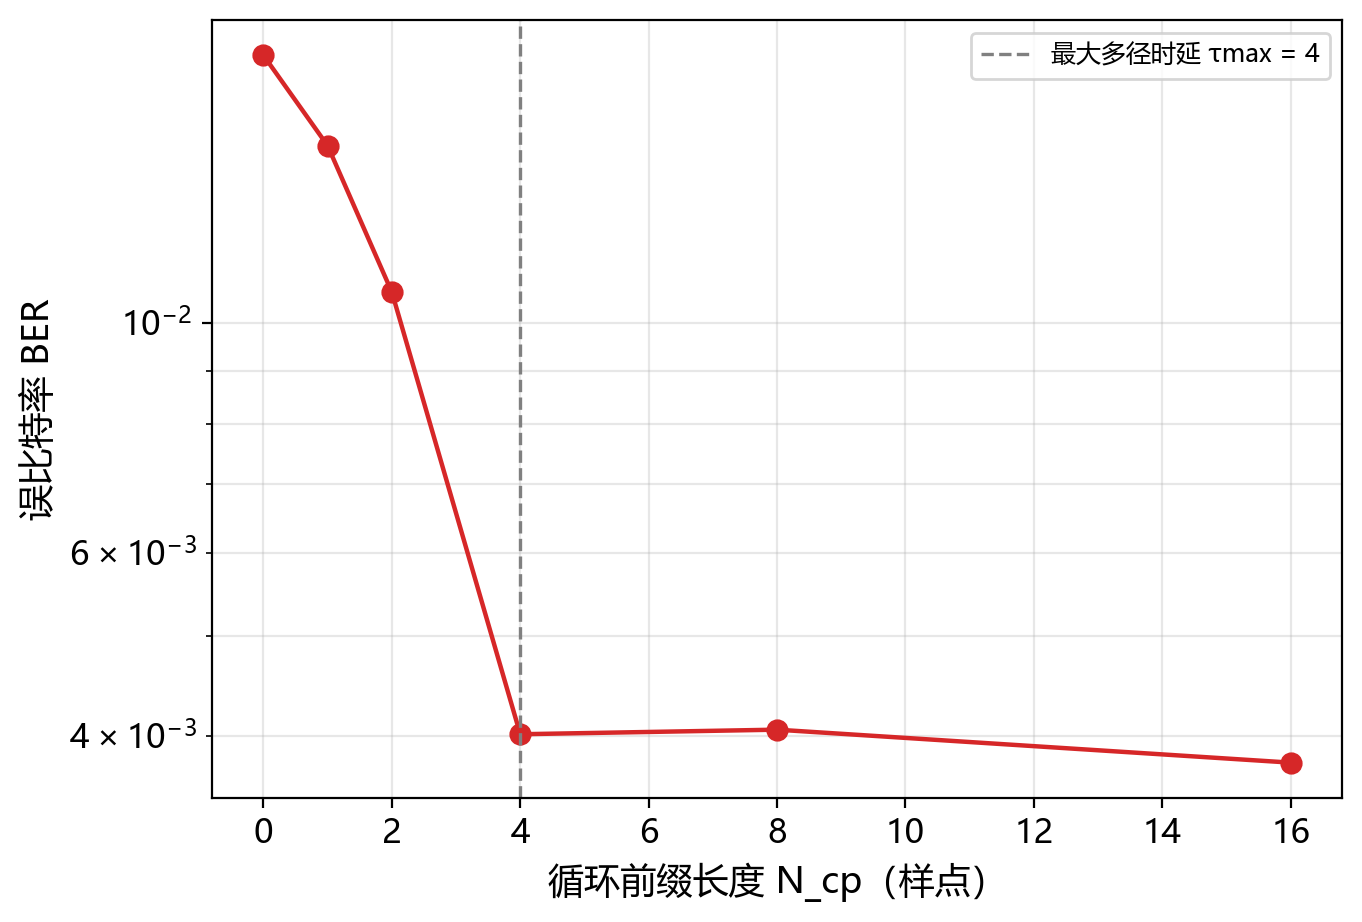

表 6  不同循环前缀长度下的 BER
 N_cp      BER
    0 0.018111
    1 0.014820
    2 0.010711
    4 0.004017
    8 0.004058
   16 0.003771
拓展实验一仿真完成并通过断言检验！


In [3]:
# 模块三（拓展实验一）：保护间隔 (CP) 长度与最大多径时延关系研究
# 完全对标教材第 28 页拓展实验 1 要求：
# “研究最大多径时延扩展 tau_m 与保护间隔 G_i (N_cp) 长度的关系。
#  分别观察当 N_cp < tau_m 和 N_cp >= tau_m 时系统 BER 性能的变化，并分析原因。”

def simulate_cp_sweep(cp_candidates, ebno_db=18.0, num_blocks=1000, symbols_per_block=8):
    """测试不同循环前缀长度下的连续 OFDM 帧传输误码率。

    采用连续符号流传输模式：前一符号的多径响应会泄漏到后一符号的前端。
    当 N_cp < tau_max 时，残留多径时延破坏正交性，引发 ISI 与 ICI，产生不可消除的误码平台。
    当 N_cp >= tau_max 时，多径时延被循环前缀完全吸收，ISI/ICI 消除。
    """
    ber_cp_list = []
    N = NUM_SUBCARRIERS
    no = ebno_db_to_no(float(ebno_db), BITS_PER_SYMBOL).item()

    for cp_len in cp_candidates:
        block_len = N + cp_len

        # 1) 发送端：QPSK -> IFFT + CP -> 连续符号流
        bits = torch.randint(
            0,
            2,
            (num_blocks, symbols_per_block, N, BITS_PER_SYMBOL),
            dtype=torch.int32,
            device=DEVICE,
        )
        freq_sym = qpsk_modulate(bits)
        time_sym = ofdm_modulate(freq_sym, cp_len)
        stream = time_sym.reshape(num_blocks, symbols_per_block * block_len)

        # 2) 3 径瑞利信道（每帧一次实现）+ AWGN
        taps = sample_multipath_taps(num_blocks)
        h_freq = channel_frequency_response(taps)
        rx_stream = apply_multipath_time(stream, taps)
        rx_stream = AWGN(precision=PRECISION, device=DEVICE)(rx_stream, no)

        # 3) 逐符号去 CP、FFT、迫零均衡、解映射与误码统计
        rx_freq = extract_ofdm_symbols(rx_stream, symbols_per_block, cp_len)
        rx_eq = zf_equalize(rx_freq, h_freq.unsqueeze(1))
        bits_hat = qpsk_demodulate(rx_eq)
        ber_cp_list.append(ber(bits, bits_hat))

    return np.array(ber_cp_list)


cp_candidates = [0, 1, 2, 4, 8, 16]
test_ebno = 18.0

print(f"正在执行拓展实验一：固定 Eb/N0 = {test_ebno} dB 下扫描循环前缀 CP 长度...")
ber_cp_results = simulate_cp_sweep(cp_candidates, ebno_db=test_ebno, num_blocks=1000, symbols_per_block=8)

# 打印数值统计
for cp, b in zip(cp_candidates, ber_cp_results):
    print(f"  CP 长度 = {cp:2d} (最大时延 tau_max={MAX_PATH_DELAY}): BER = {b:.5e}")

# 绘制 CP 长度与 BER 关系曲线，并在 x = MAX_PATH_DELAY 处绘制垂直虚线辅助线
fig, ax = plt.subplots(figsize=(7.0, 4.8))
ax.semilogy(cp_candidates, ber_cp_results, "o-", lw=1.6, ms=7, color="#d62728")
ax.axvline(MAX_PATH_DELAY, color="gray", ls="--", lw=1.2, label=f"最大多径时延 τmax = {MAX_PATH_DELAY}")
ax.set_xlabel("循环前缀长度 N_cp（样点）")
ax.set_ylabel("误比特率 BER")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "03A_cp_sweep.png", dpi=200, bbox_inches="tight")
print("图11  BER 随循环前缀长度的变化（Eb/N0 = 18 dB）")
plt.show()

# 数值表（结果性数据）
import pandas as pd

df_cp = pd.DataFrame({"N_cp": cp_candidates, "BER": ber_cp_results})
print("表 6  不同循环前缀长度下的 BER")
print(df_cp.to_string(index=False))
df_cp.to_csv(DATA_DIR / "03A_cp_sweep.csv", index=False, encoding="utf-8-sig")

# 验证断言：无 CP 或 CP 过短时的误码率显著高于满足条件的 CP
assert ber_cp_results[0] > ber_cp_results[-1], "无 CP 时的 BER 应显著高于充分 CP"
assert ber_cp_results[3] < ber_cp_results[0] * 0.5, "当 CP >= tau_max 时误码率应大幅降低"
print("拓展实验一仿真完成并通过断言检验！")


正在执行拓展实验二：导频插入与 LS 信道估计性能仿真...


图12  理想 CSI 与基于导频 LS 估计的 OFDM 误码性能对比


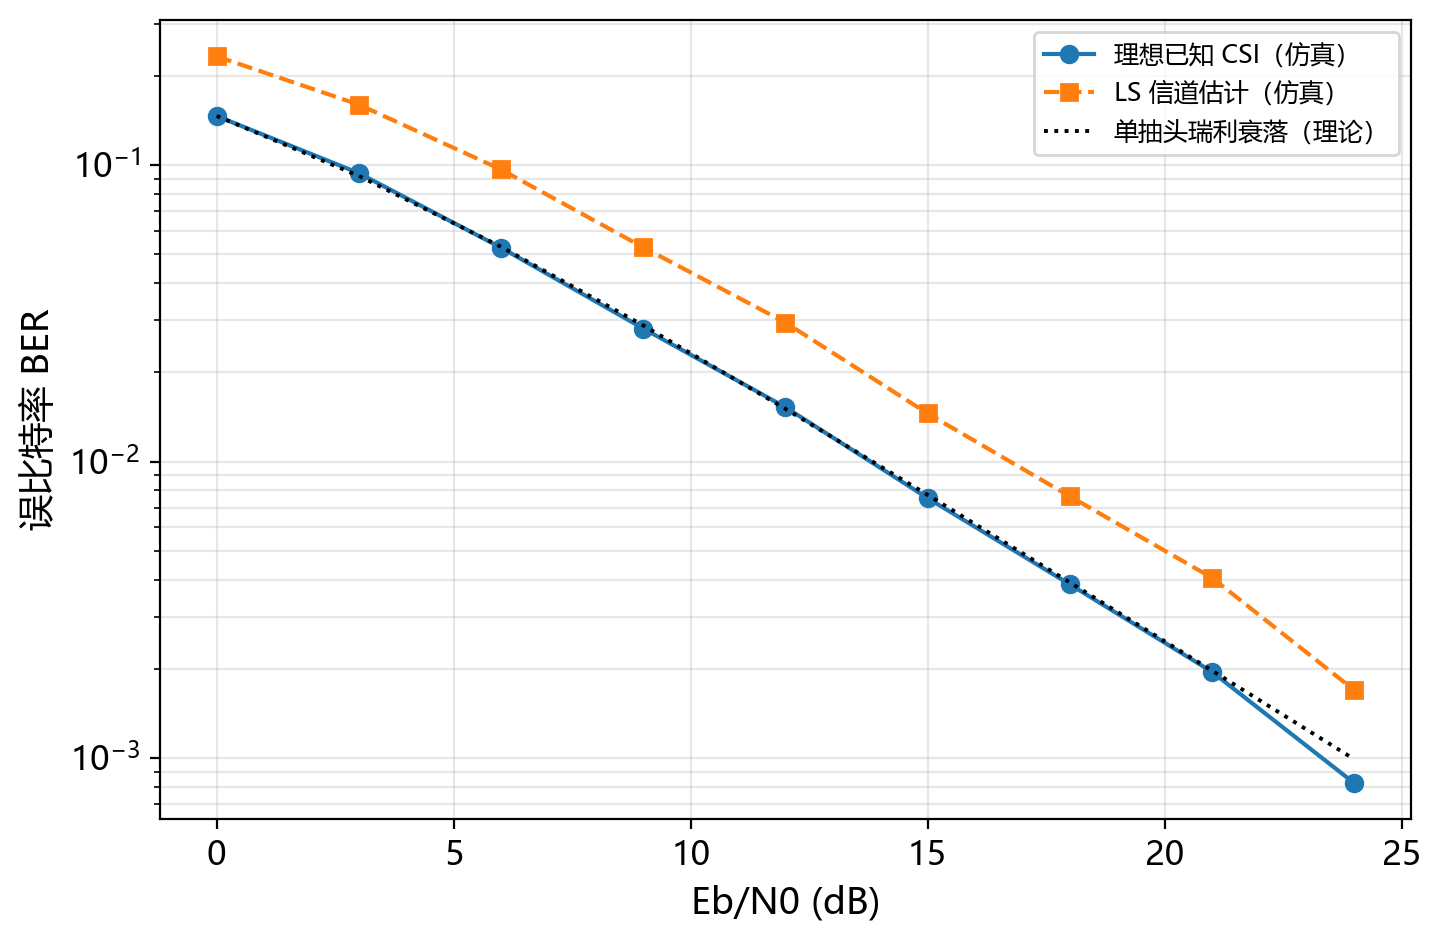

表 7  理想 CSI 与 LS 信道估计的 BER 对比
 EbN0_dB  BER_理想CSI  BER_LS估计  BER_单抽头瑞利理论
       0   0.146313  0.232529     0.146447
       3   0.093887  0.159842     0.091913
       6   0.052652  0.096602     0.052999
       9   0.028107  0.052779     0.028782
      12   0.015256  0.029437     0.015065
      15   0.007533  0.014531     0.007723
      18   0.003855  0.007639     0.003916
      21   0.001955  0.004059     0.001974
      24   0.000824  0.001697     0.000992
拓展实验二仿真完成并通过断言检验！


In [4]:
# 模块四（拓展实验二）：导频插入与 LS 信道估计性能对比
# 完全对标教材第 28 页拓展实验 2 要求：
# “以上实验假定信道信息在接收端是理想已知的。请修改仿真程序，通过插入导频 (Pilot)
#  的方式进行信道估计，并使用估计出的信道信息进行均衡。比较此时的 BER 性能与理想信道已知情况下的性能差异。”

def simulate_ls_channel_estimation(ebno_db_range, num_blocks=1000, data_symbols_per_block=4):
    """块状导频传输结构下的 LS 信道估计与理想已知 CSI 对比实验。

    每个传输块包含: 1 个已知块状导频符号 X_p + data_symbols_per_block 个数据符号 X_d。
    在信道相干时间内，导频与数据经历相同的信道响应 H[k]。
    接收端利用导频通过最小二乘估计算法: H_hat_ls[k] = Y_p[k] / X_p[k] 进行信道估计，
    然后使用 H_hat_ls[k] 均衡数据符号。
    """
    ber_ideal_list = []
    ber_ls_list = []

    N = NUM_SUBCARRIERS
    cp = DEFAULT_CP_LEN
    block_len = N + cp
    num_symbols = 1 + data_symbols_per_block

    for ebno_db in ebno_db_range:
        no = ebno_db_to_no(float(ebno_db), BITS_PER_SYMBOL).item()

        # 1) 构造已知导频符号与数据符号并拼接成一个发送块
        pilot_bits = torch.randint(0, 2, (num_blocks, N, BITS_PER_SYMBOL), dtype=torch.int32, device=DEVICE)
        pilot_sym = qpsk_modulate(pilot_bits)                                    # (B, N)
        data_bits = torch.randint(
            0,
            2,
            (num_blocks, data_symbols_per_block, N, BITS_PER_SYMBOL),
            dtype=torch.int32,
            device=DEVICE,
        )
        data_sym = qpsk_modulate(data_bits)                                      # (B, D, N)
        block_sym = torch.cat([pilot_sym.unsqueeze(1), data_sym], dim=1)         # (B, S, N)

        # 2) OFDM 调制 + 多径信道 + AWGN
        time_sym = ofdm_modulate(block_sym, cp)
        stream = time_sym.reshape(num_blocks, num_symbols * block_len)
        taps = sample_multipath_taps(num_blocks)
        h_freq = channel_frequency_response(taps)                                # (B, N)
        rx_stream = apply_multipath_time(stream, taps)
        rx_stream = AWGN(precision=PRECISION, device=DEVICE)(rx_stream, no)
        rx_freq = extract_ofdm_symbols(rx_stream, num_symbols, cp)               # (B, S, N)

        # 3) 导频位置最小二乘信道估计: H_hat = Y_p / X_p
        y_pilot = rx_freq[:, 0, :]
        h_ls = y_pilot / (pilot_sym + 1e-12)

        # 4) 分别用理想 CSI 与 LS 估计 CSI 均衡数据符号
        y_data = rx_freq[:, 1:, :]
        rx_eq_ideal = zf_equalize(y_data, h_freq.unsqueeze(1))
        rx_eq_ls = zf_equalize(y_data, h_ls.unsqueeze(1))

        ber_ideal_list.append(ber(data_bits, qpsk_demodulate(rx_eq_ideal)))
        ber_ls_list.append(ber(data_bits, qpsk_demodulate(rx_eq_ls)))

    return np.array(ber_ideal_list), np.array(ber_ls_list)


ebno_range_ls = np.arange(0, 25, 3)

print("正在执行拓展实验二：导频插入与 LS 信道估计性能仿真...")
ber_ideal_results, ber_ls_results = simulate_ls_channel_estimation(ebno_range_ls, num_blocks=1000, data_symbols_per_block=4)

# 绘制 BER 对比图 (包含理想已知 CSI、LS 估计 CSI 与理论瑞利参考线)
fig, ax = plt.subplots(figsize=(7.4, 4.9))
ax.semilogy(ebno_range_ls, ber_ideal_results, "o-", lw=1.5, ms=6, label="理想已知 CSI（仿真）")
ax.semilogy(ebno_range_ls, ber_ls_results, "s--", lw=1.5, ms=6, label="LS 信道估计（仿真）")
ax.semilogy(ebno_range_ls, theory_rayleigh_ber(ebno_range_ls), "k:", lw=1.4, label="单抽头瑞利衰落（理论）")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "03A_ls_estimation.png", dpi=200, bbox_inches="tight")
print("图12  理想 CSI 与基于导频 LS 估计的 OFDM 误码性能对比")
plt.show()

# 数值表（结果性数据）
import pandas as pd

df_ls = pd.DataFrame(
    {
        "EbN0_dB": ebno_range_ls,
        "BER_理想CSI": ber_ideal_results,
        "BER_LS估计": ber_ls_results,
        "BER_单抽头瑞利理论": theory_rayleigh_ber(ebno_range_ls),
    }
)
print("表 7  理想 CSI 与 LS 信道估计的 BER 对比")
print(df_ls.to_string(index=False))
df_ls.to_csv(DATA_DIR / "03A_ls_estimation.csv", index=False, encoding="utf-8-sig")

# 验证断言：LS 估计性能略差于理想已知信道（噪声引入估计误差），但在高信噪比下整体趋势一致
assert len(ber_ls_results) == len(ebno_range_ls), "结果长度不匹配"
assert ber_ls_results[0] > ber_ls_results[-1], "LS 估计 BER 应随 Eb/N0 提升而下降"
assert np.all(ber_ls_results >= ber_ideal_results * 0.9), "LS 估计引入信道估计噪声，BER 应普遍高于或接近理想 CSI"
print("拓展实验二仿真完成并通过断言检验！")


## 补充：OFDM 关键过程可视化

为便于在报告中说明 OFDM 的时域结构、频域子载波与均衡效果，这里补充输出时域波形（含 CP 区间）、
子载波与信道频响，以及迫零均衡前后的接收星座图。


图7  OFDM 符号的时域波形与循环前缀结构


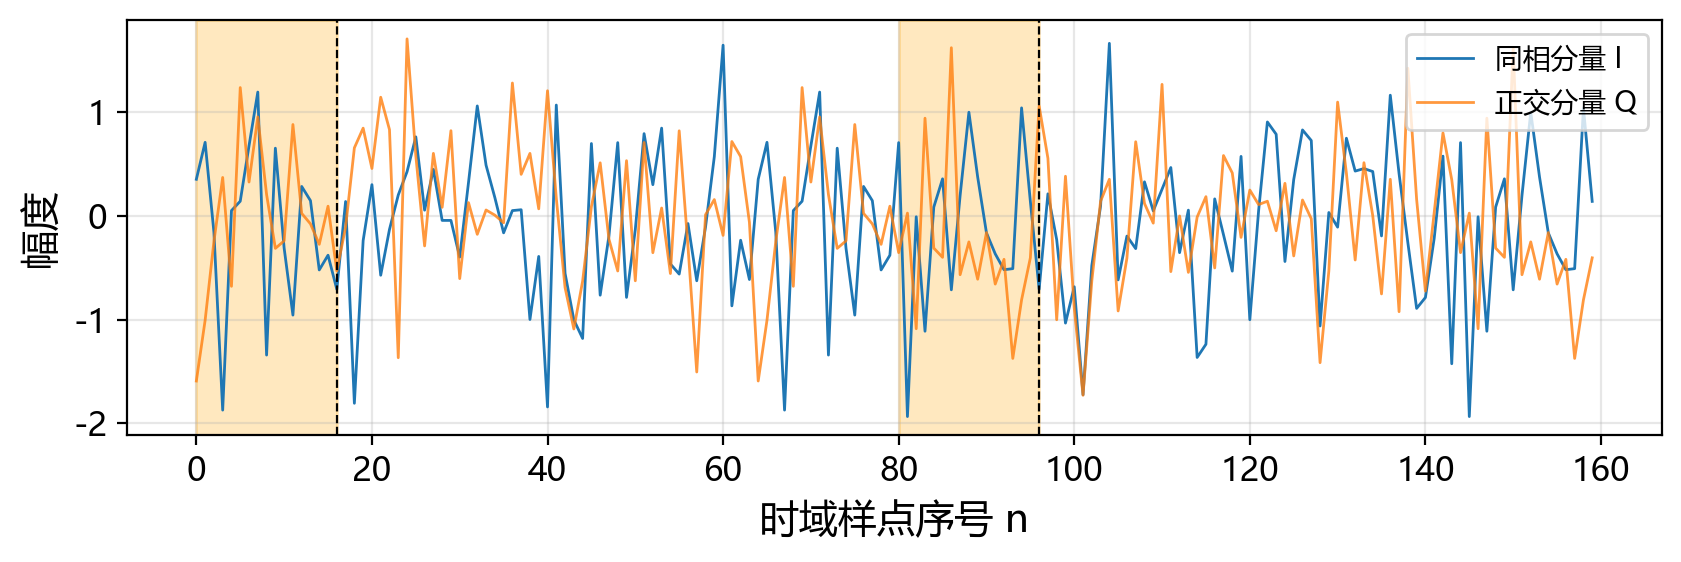

图8  三径信道的频率响应与子载波位置

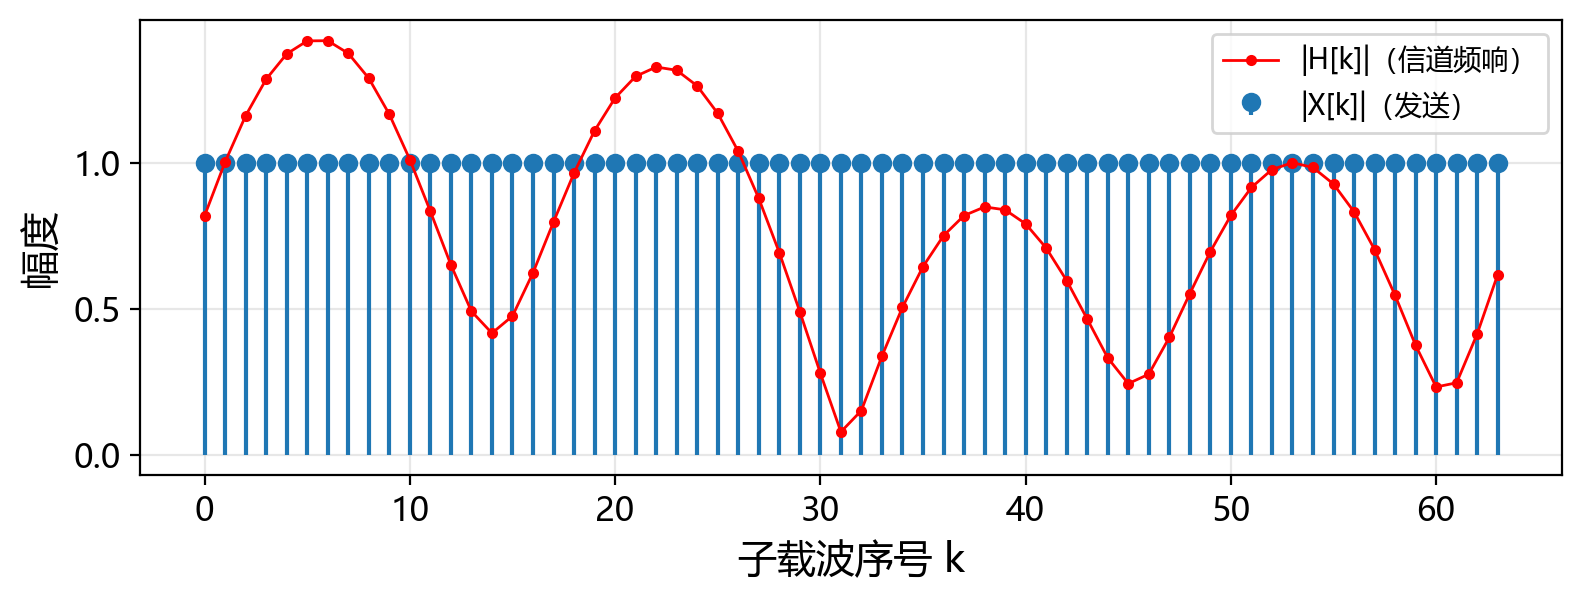

图9  OFDM 接收端 ZF 均衡前后的星座图（Eb/N0 = 20 dB）


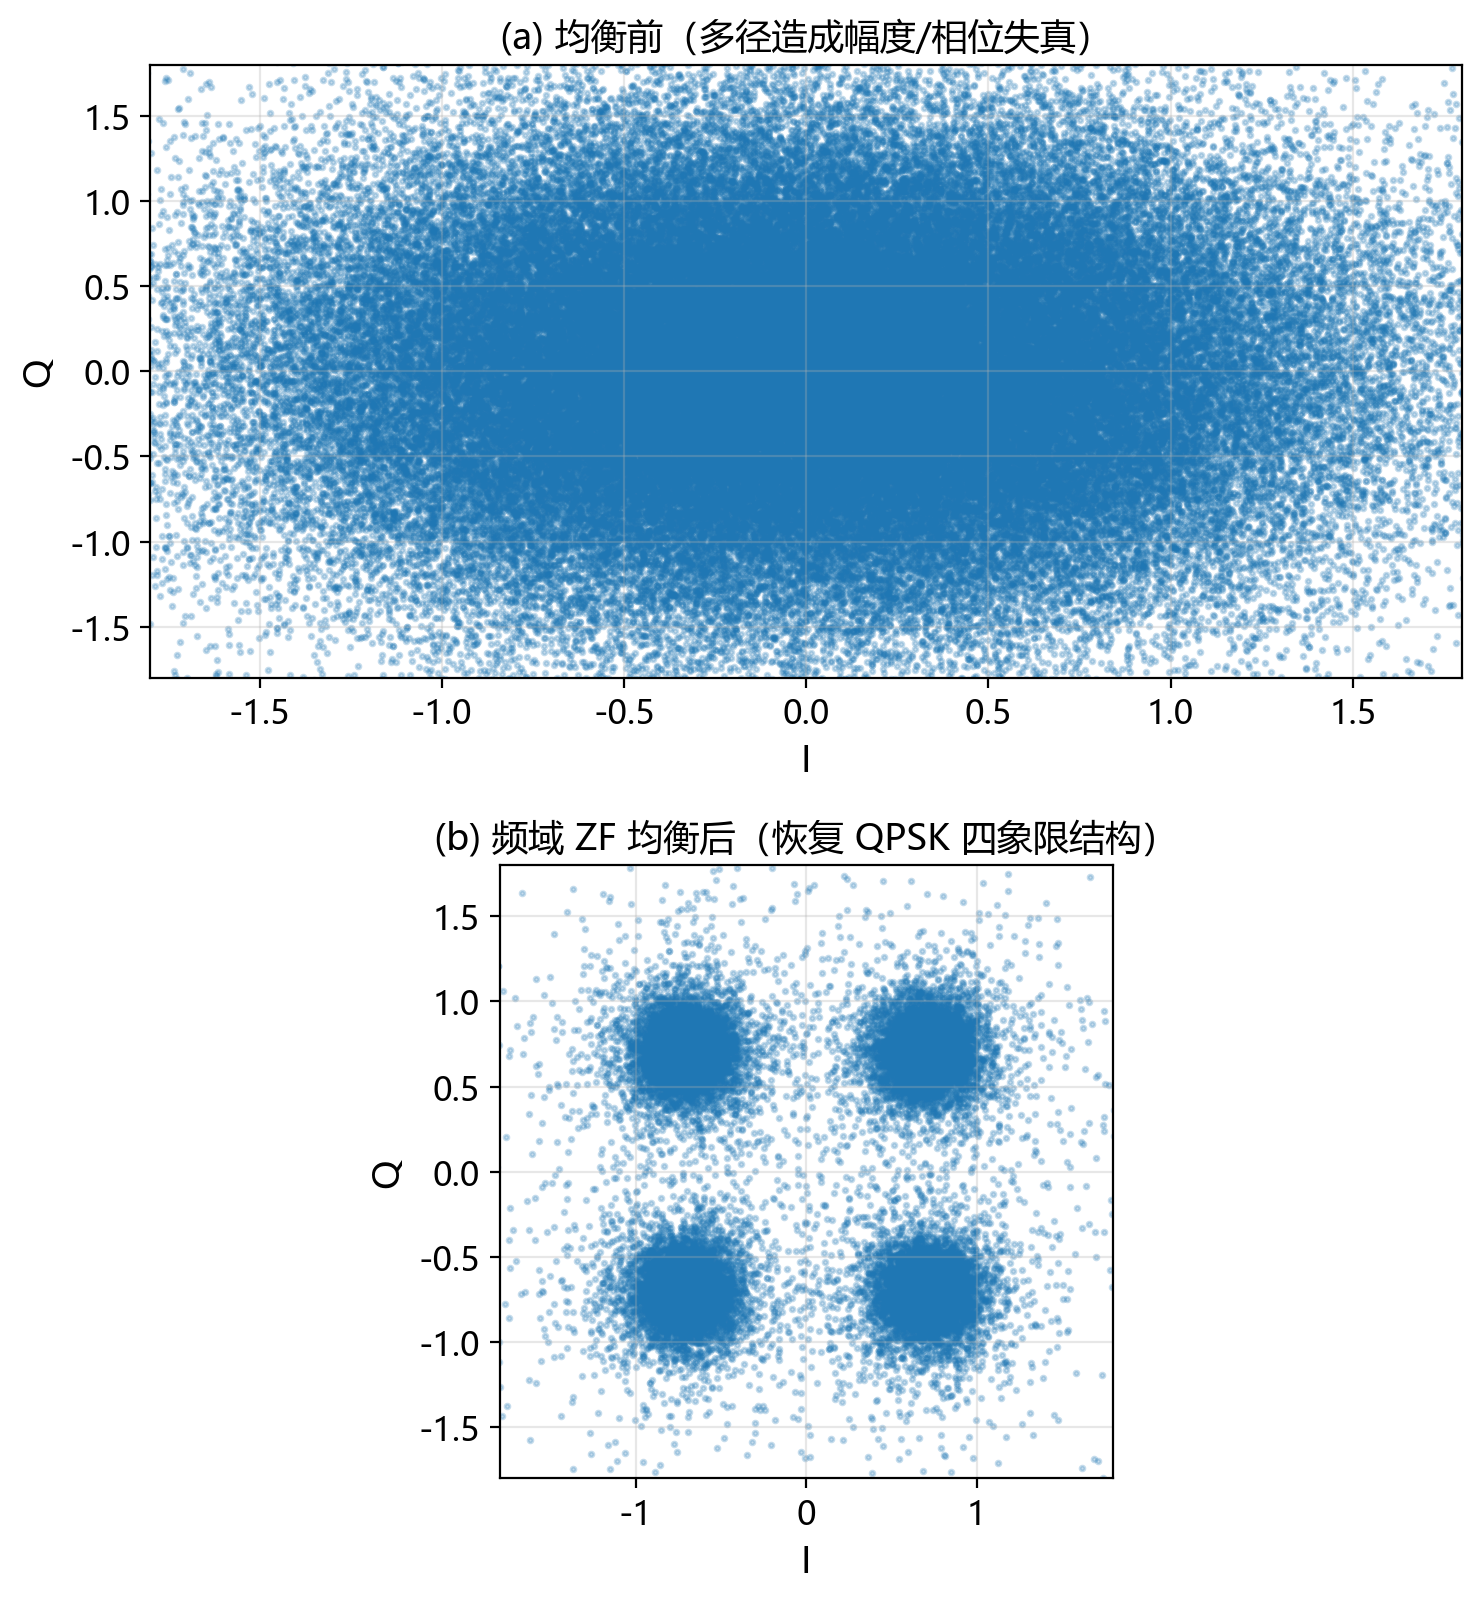

In [5]:
# 补充（过程性材料）：OFDM 时域符号结构与循环前缀示意、频域子载波与多径信道频响。
set_seed(2026)

N = NUM_SUBCARRIERS
cp = DEFAULT_CP_LEN

# --- 图 9(a)：两个连续 OFDM 符号的时域波形与 CP 区间 ---
bits2 = torch.randint(0, 2, (1, 2, N, BITS_PER_SYMBOL), dtype=torch.int32, device=DEVICE)
sym2 = qpsk_modulate(bits2)
x2 = ofdm_modulate(sym2, cp).reshape(-1)      # 2 * (N + cp) 个时域样点

fig, ax = plt.subplots(figsize=(8.6, 3.0))
ax.plot(np.arange(x2.numel()), x2.real.cpu().numpy(), lw=1.0, label="同相分量 I")
ax.plot(np.arange(x2.numel()), x2.imag.cpu().numpy(), lw=1.0, alpha=0.8, label="正交分量 Q")
for s in range(2):
    start = s * (N + cp)
    ax.axvspan(start, start + cp, color="orange", alpha=0.25)
    ax.axvline(start + cp, color="k", ls="--", lw=0.8)
ax.set_xlabel("时域样点序号 n", fontsize=14)
ax.set_ylabel("幅度", fontsize=14)
ax.tick_params(labelsize=12)
ax.legend(fontsize=10, loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "03A_time_cp_structure.png", dpi=200, bbox_inches="tight")
print("图7  OFDM 符号的时域波形与循环前缀结构")
plt.show()

# --- 图 9(b)：各子载波幅度与 3 径信道频域响应 ---
taps = sample_multipath_taps(1)
h_freq = channel_frequency_response(taps)[0].cpu().numpy()
k = np.arange(N)

fig, ax = plt.subplots(figsize=(8.2, 3.2))
ax.stem(k, np.abs(sym2[0, 0].cpu().numpy()), basefmt=" ", label="|X[k]|（发送）")
ax.plot(k, np.abs(h_freq), "r.-", lw=1.0, label="|H[k]|（信道频响）")
ax.set_xlabel("子载波序号 k", fontsize=14)
ax.set_ylabel("幅度", fontsize=14)
ax.tick_params(labelsize=12)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "03A_freq_response.png", dpi=200, bbox_inches="tight")
print("图8  三径信道的频率响应与子载波位置")
plt.show()

# --- 图 9(c)：单抽头均衡前后接收星座图 ---
# 取较高的 Eb/N0（20 dB）：低信噪比下 ZF 会把深衰落子载波的噪声放大，
# 四个簇彼此重叠，不利于展示均衡恢复相位结构的效果。
ebb = 20.0
no8 = ebno_db_to_no(ebb, BITS_PER_SYMBOL).item()
bits3 = torch.randint(0, 2, (2000, NUM_SUBCARRIERS, BITS_PER_SYMBOL), dtype=torch.int32, device=DEVICE)
sym3 = qpsk_modulate(bits3)
ts = ofdm_modulate(sym3, cp)
st = ts.reshape(2000, N + cp)
tp = sample_multipath_taps(2000)
hf = channel_frequency_response(tp)
rx = AWGN(precision=PRECISION, device=DEVICE)(apply_multipath_time(st, tp), no8)
rf = extract_ofdm_symbols(rx, 1, cp)
rx_eq = zf_equalize(rf, hf.unsqueeze(1))

# 深衰落子载波 |H[k]| 很小，ZF 均衡会把噪声放大成离群点；
# 这里不截断数据，而是用坐标轴范围把离群点裁掉（比截断更干净，也不改变 BER 统计）。
eq_re = rx_eq[:, 0, :].real.cpu().flatten()
eq_im = rx_eq[:, 0, :].imag.cpu().flatten()

fig, axes = plt.subplots(2, 1, figsize=(7.6, 8.2))
axes[0].scatter(rf[:, 0, :].real.cpu().flatten(), rf[:, 0, :].imag.cpu().flatten(), s=3, alpha=0.25)
axes[0].set_title("(a) 均衡前（多径造成幅度/相位失真）", fontsize=13)
axes[1].scatter(eq_re, eq_im, s=3, alpha=0.25)
axes[1].set_title("(b) 频域 ZF 均衡后（恢复 QPSK 四象限结构）", fontsize=13)
for ax in axes:
    ax.set_xlabel("I", fontsize=13)
    ax.set_ylabel("Q", fontsize=13)
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.3)
    ax.set_xlim(-1.8, 1.8)
    ax.set_ylim(-1.8, 1.8)
axes[1].set_aspect("equal")
plt.tight_layout()
plt.savefig(FIG_DIR / "03A_constellation_eq.png", dpi=200, bbox_inches="tight")
print("图9  OFDM 接收端 ZF 均衡前后的星座图（Eb/N0 = 20 dB）")
plt.show()
